# ReW contra R-KalWeNN, comparação pareada

Cada modelo varia **só o que é dele**. A Regression WiSARD varre as médias da
família dela; o R-KalWeNN varre as covariâncias do filtro e as médias `K`, que
são as ponderadas. As duas famílias não se misturam em ponto nenhum.

Os dois compartilham a binarização, o `mapping` e o split, e a mesma seed
sorteia o mesmo `mapping` para os dois, então a comparação é pareada.

| seção | conteúdo |
|---|---|
| 1 | configuração, tudo numa célula |
| 2 | definições, iguais às do notebook 06 |
| 3 | dados, pipeline do `houseprice.py`, alvo em `log1p` |
| 4 | avaliação vetorizada das duas famílias, conferida contra as classes |
| 5 | o experimento |
| 6 | resultados |

---
# Seção 1 — Configuração

Tudo o que se mexe está nesta célula.

In [65]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COR_REW, COR_KAL, COR_REF = "#B4674D", "#2F6B6A", "#8A8F98"

# ── dados ────────────────────────────────────────────────────────────────────
BASE_DADOS   = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"
TEST_SIZE    = 0.33          # houseprice.py
RANDOM_STATE = 0             # houseprice.py
REF_ARTIGO   = 0.278         # Neurocomputing 416 (2020), Tabela 2, ReW Median

# ═══════════════ O QUE VARIA ═════════════════════════════════════════════════

# ── codificação, compartilhada pelos dois modelos ────────────────────────────
# 27 e 6 são os da tese. Nem todo par divide a retina de forma exata; o
# `sorteia_mapping` descarta os bits que sobram, no máximo 8 de 6640, 0,1%.
EXP_THERM = [20, 25, 27]
EXP_ADDR  = [6, 8, 12]

# ── ReW: varia só as médias dela ─────────────────────────────────────────────
EXP_MEDIAS_REW = ["SimpleMean", "PowerMean(2)", "HarmonicMean",
                  "HarmonicPower(2)", "ExponentialMean", "Median"]

# ── R-KalWeNN: varia as covariâncias e as médias dele ────────────────────────
EXP_MEDIAS_KAL = ["KSimpleMean", "KPowerMean(2)", "KHarmonicMean",
                  "KHarmonicPower(2)", "KExponentialMean", "KMedian"]

EXP_X0_C, EXP_X0_Y = 0.0, 0.0
EXP_PASSO_PREDICAO = "visita"      # q_y por acesso; "exemplo" = por exemplo

EXP_Q_C  = [1e-6, 1e-4]            # filtro do peso
EXP_R_C  = [0.1, 1.0]
EXP_P0_C = [0.1, 1.0]

EXP_Q_Y  = [1.5e-3, 1.5e-1]        # filtro da estimativa
EXP_R_Y  = [1.0, 12.0]
EXP_P0_Y = [12.0, 144.0]

# ── repetições: a seed sorteia o mapping E a ordem de treino, nos dois ───────
EXP_SEEDS = (0, 1, 2)

EXP_ARQUIVO = "comparacao_rew_rkalwenn.csv"

# ═══════════════ tamanho e custo ═════════════════════════════════════════════
PARES = [(t, a) for t in EXP_THERM for a in EXP_ADDR]
N_KAL = (len(EXP_Q_C) * len(EXP_R_C) * len(EXP_P0_C) *
         len(EXP_Q_Y) * len(EXP_R_Y) * len(EXP_P0_Y))

print("CODIFICAÇÃO\n")
print(f"  {'therm':>6}{'address':>9}{'retina':>9}{'RAM nodes':>11}{'bits descartados':>18}")
for t, a in PARES:
    r = t * 332
    print(f"  {t:>6}{a:>9}{r:>9}{r//a:>11}{r - (r//a)*a:>18}")

print(f"\nReW        : {len(EXP_MEDIAS_REW)} médias")
print(f"R-KalWeNN  : {N_KAL} covariâncias x {len(EXP_MEDIAS_KAL)} médias "
      f"(as médias saem do mesmo ajuste)")
print(f"seeds      : {len(EXP_SEEDS)}   (sorteiam mapping e ordem de treino)")
print(f"passo de predição do filtro de y: {EXP_PASSO_PREDICAO!r}")
print(f"\najustes do R-KalWeNN: {len(PARES)} x {N_KAL} x {len(EXP_SEEDS)} = "
      f"{len(PARES)*N_KAL*len(EXP_SEEDS):,}")
print(f"linhas na tabela final: "
      f"{len(PARES)*len(EXP_SEEDS)*(len(EXP_MEDIAS_REW) + N_KAL*len(EXP_MEDIAS_KAL)):,}")

CODIFICAÇÃO

   therm  address   retina  RAM nodes  bits descartados
      20        6     6640       1106                 4
      20        8     6640        830                 0
      20       12     6640        553                 4
      25        6     8300       1383                 2
      25        8     8300       1037                 4
      25       12     8300        691                 8
      27        6     8964       1494                 0
      27        8     8964       1120                 4
      27       12     8964        747                 0

ReW        : 6 médias
R-KalWeNN  : 64 covariâncias x 6 médias (as médias saem do mesmo ajuste)
seeds      : 3   (sorteiam mapping e ordem de treino)
passo de predição do filtro de y: 'visita'

ajustes do R-KalWeNN: 9 x 64 x 3 = 1,728
linhas na tabela final: 10,530


---
# Seção 2 — Definições

Idênticas às do notebook 06: thermometer, as duas famílias de média,
endereçamento, Regression WiSARD e R-KalWeNN.

In [66]:
class DynamicThermometer:
    """Termômetro por atributo, com faixa própria para cada um."""

    def __init__(self, sizes, minimos, maximos):
        self.sizes = list(sizes)
        self.limiares = []
        for n, mn, mx in zip(self.sizes, minimos, maximos):
            passo = (mx - mn) / n
            v, faixa = mn, []
            for _ in range(n):                # acumula, como o math::ranges
                faixa.append(v)
                v += passo
            self.limiares.append(np.asarray(faixa, dtype=float))
        self.size = int(np.sum(self.sizes))

    def transform(self, X):
        """(n_amostras, n_atributos) float -> (n_amostras, size) uint8."""
        X = np.atleast_2d(np.asarray(X, dtype=float))
        saida = np.empty((len(X), self.size), dtype=np.uint8)
        k = 0
        for i, faixa in enumerate(self.limiares):
            n = len(faixa)
            saida[:, k:k + n] = (X[:, [i]] > faixa[None, :]).astype(np.uint8)
            k += n
        return saida


print("DynamicThermometer definido")

DynamicThermometer definido


In [67]:
# ─────────────────────────── família ReW ─────────────────────────────────────
class Mean:
    """`output_rams` é uma lista de [contador, soma_y], incluindo as RAM nodes
    não visitadas como [0, 0], como no predict da referência."""
    nome = "Mean"
    def calculate(self, output_rams):
        raise NotImplementedError
    def __repr__(self):
        return f"ReW.{self.nome}"


class SimpleMean(Mean):
    nome = "SimpleMean"
    def calculate(self, output_rams):
        sc = sum(c for c, _ in output_rams)
        sy = sum(y for _, y in output_rams)
        return sy / sc if sc > 0 else 0.0


class PowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += (y / c) ** self.power; m += 1
        return (s / m) ** (1.0 / self.power) if m > 0 else 0.0


class HarmonicMean(Mean):
    nome = "HarmonicMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / mu; m += 1
        return m / s if m > 0 else 0.0


class HarmonicPowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / (mu ** self.power); m += 1
        return (m / s) ** (1.0 / self.power) if m > 0 else 0.0


class ExponentialMean(Mean):
    nome = "ExponentialMean"
    def calculate(self, output_rams):
        e, m = 1.0, 0                          # começa em 1, como na referência
        for c, y in output_rams:
            if c != 0:
                e += np.exp(y / c); m += 1
        return float(np.log(e / m)) if m > 0 else 0.0


class Median(Mean):
    """Porte do Median::calculate do wisardpkg, que é o que a tese executou.

    Divide sem checar contador zero, ao contrário das outras médias, e usa
    índice deslocado em um. Onde a referência leria fora do vetor, aqui devolve
    NaN em vez de ler lixo de memória, e os NaN vão para o fim da ordenação.
    """
    nome = "Median"
    def calculate(self, output_rams):
        mus = [np.divide(float(y), float(c)) if c != 0 else float("nan")
               for c, y in output_rams]
        mus = sorted(mus, key=lambda v: (np.isnan(v), v))
        n = len(mus)
        if n % 2 == 0:
            i = n // 2
            return (mus[i] + mus[i + 1]) / 2.0 if i + 1 < n else float("nan")
        i = (n - 1) // 2 + 1
        return mus[i] if i < n else float("nan")


def medias_rew():
    return {"SimpleMean": SimpleMean(), "PowerMean(2)": PowerMean(2),
            "HarmonicMean": HarmonicMean(), "HarmonicPower(2)": HarmonicPowerMean(2),
            "ExponentialMean": ExponentialMean(), "Median": Median()}


print("médias da família ReW:", ", ".join(medias_rew()))

médias da família ReW: SimpleMean, PowerMean(2), HarmonicMean, HarmonicPower(2), ExponentialMean, Median


In [68]:
# ────────────────────── família R-KalWeNN (ponderadas) ───────────────────────
class MediaPonderada:
    """`pares` é uma lista de (c_k, y_k) das células COM evidência.

    c_k é confiança em [0,1), y_k é o valor esperado local.
    Todas normalizam por sum(c), o que mantém o resultado na escala do alvo.
    """
    nome = "MediaPonderada"
    def calculate(self, pares):
        raise NotImplementedError
    def __repr__(self):
        return self.nome


class PondSimpleMean(MediaPonderada):
    nome = "KSimpleMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        return sum(c * y for c, y in pares) / sc if sc > 0 else np.nan


class PondPowerMean(MediaPonderada):
    def __init__(self, power=2):
        self.power = power; self.nome = f"KPowerMean({power})"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return (sum(c * y ** self.power for c, y in pares) / sc) ** (1.0 / self.power)


class PondHarmonicMean(MediaPonderada):
    nome = "KHarmonicMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y
        return sc / s if s > 0 else np.nan


class PondHarmonicPowerMean(MediaPonderada):
    def __init__(self, power=2):
        self.power = power; self.nome = f"KHarmonicPower({power})"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y ** self.power
        return (sc / s) ** (1.0 / self.power) if s > 0 else np.nan


class PondExponentialMean(MediaPonderada):
    nome = "KExponentialMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return float(np.log(sum(c * np.exp(y) for c, y in pares) / sc))


class PondMedian(MediaPonderada):
    """Mediana ponderada: y onde o c acumulado cruza metade de sum(c)."""
    nome = "KMedian"
    def calculate(self, pares):
        pares = sorted(pares, key=lambda t: t[1])
        total = sum(c for c, _ in pares)
        if total <= 0:
            return np.nan
        meio, acum = total / 2.0, 0.0
        for c, y in pares:
            acum += c
            if acum >= meio:
                return y
        return pares[-1][1]


def medias_kal():
    """Prefixo K: fórmulas ponderadas, desenhadas para o R-KalWeNN.

    Não são as da Regression WiSARD, que estão em `medias_rew()`."""
    return {"KSimpleMean": PondSimpleMean(), "KPowerMean(2)": PondPowerMean(2),
            "KHarmonicMean": PondHarmonicMean(),
            "KHarmonicPower(2)": PondHarmonicPowerMean(2),
            "KExponentialMean": PondExponentialMean(), "KMedian": PondMedian()}


print("médias da família R-KalWeNN:", ", ".join(medias_kal()))

médias da família R-KalWeNN: KSimpleMean, KPowerMean(2), KHarmonicMean, KHarmonicPower(2), KExponentialMean, KMedian


In [69]:
class Retina:
    """Converte entrada binarizada em endereços, um por RAM node."""

    def __init__(self, address_size, mapping):
        self.address_size = int(address_size)
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, self.address_size)
        self.n_rams = self.mapping.shape[0]
        self.n_addr = 1 << self.address_size
        self._pesos = 1 << np.arange(self.address_size)     # LSB primeiro

    def enderecos(self, Xb):
        """(n, retina) uint8 -> (n, n_rams) int."""
        Xb = np.asarray(Xb, dtype=np.uint8)
        return (Xb[:, self.mapping] * self._pesos).sum(axis=2).astype(np.int64)


def sorteia_mapping(retina_bits, address_size, seed=0):
    """Permutação dos bits da retina, truncada a um múltiplo de address_size."""
    n_rams = retina_bits // address_size
    rng = np.random.default_rng(seed)
    return rng.permutation(retina_bits)[: n_rams * address_size].tolist()


print("Retina definida")

Retina definida


In [70]:
class RegressionWiSARD:
    """Regression WiSARD. Recebe entrada já binarizada."""

    def __init__(self, address_size, mean, mapping):
        self.retina = Retina(address_size, mapping)
        self.mean = mean

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        self._mem = [dict() for _ in range(self.n_rams_)]
        for i in range(len(y)):
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is None:
                    self._mem[r_][addr[i, r_]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0; cel[1] += y[i]
        return self

    def predict(self, Xb):
        addr = self.retina.enderecos(Xb)
        vazia = [0.0, 0.0]
        return np.array([
            self.mean.calculate([self._mem[r_].get(addr[i, r_], vazia)
                                 for r_ in range(self.n_rams_)])
            for i in range(len(addr))])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 24    # chave + 2 floats


print("RegressionWiSARD definida (não é executada neste notebook)")

RegressionWiSARD definida (não é executada neste notebook)


In [71]:
class IndiceRK:
    """(ram, address) -> slot compacto, construído uma vez por (retina, treino).

    Só existem células que algum exemplo de treino visitou, o que vale para
    qualquer `address_size`: uma tabela densa de 2^address entradas por RAM node
    seria impossível já com 20 bits.
    """

    def __init__(self, retina, addr_fit):
        self.retina = retina
        self.slots_fit = np.empty_like(addr_fit)
        self._tab, off = [], 0
        for r_ in range(retina.n_rams):
            uniq, inv = np.unique(addr_fit[:, r_], return_inverse=True)
            self.slots_fit[:, r_] = inv + off
            self._tab.append((uniq, off))
            off += len(uniq)
        self.n_celulas = off

    def slots(self, addr):
        """(n, n_rams), com -1 onde o endereço não apareceu no treino."""
        out = np.full(addr.shape, -1, dtype=np.int64)
        for r_ in range(self.retina.n_rams):
            uniq, off = self._tab[r_]
            pos = np.clip(np.searchsorted(uniq, addr[:, r_]), 0, len(uniq) - 1)
            ok = uniq[pos] == addr[:, r_]
            out[ok, r_] = off + pos[ok]
        return out


print("IndiceRK definido")

IndiceRK definido


In [72]:
class RKalWeNN:
    """R-KalWeNN: Kalman nos dois campos da célula. Memória esparsa.

    FILTRO DO PESO c   observação z = 1 no acesso; célula não acessada não é
                       tocada. Como a recursão da covariância não contém z, o
                       estado c é função determinística do NÚMERO de visitas:

                           c(n) = 1 - prod_{j=1..n} (1 - kappa_j)

                       então ele é montado no fim, a partir dos contadores, sem
                       precisar de laço por exemplo.

    FILTRO DA ESTIMATIVA y   correção só no acesso. O passo de predição tem duas
                       semânticas, escolhidas por `passo_predicao`:

                       "visita"  (padrão) p_y cresce q_y uma vez por acesso.
                                 q_y/r_y age direto e a mesma faixa produz
                                 ganho útil em célula rara e em célula densa.

                       "exemplo" p_y cresce q_y a cada exemplo do treino, mesmo
                                 sem acesso. Entre dois acessos de uma célula de
                                 n visitas passam ~N/n exemplos, então o que age
                                 é q_y/r_y * N/n: célula de 6 visitas satura em
                                 q_y/r_y = 1e-2 enquanto célula de 543 ainda tem
                                 ganho 0,018. Não existe valor que deixe as duas
                                 pontas num regime útil ao mesmo tempo.

    As duas coisas juntas deixam a memória esparsa: só existem células que algum
    exemplo de treino visitou. Não há teto no `address_size`.
    """

    def __init__(self, address_size, mapping, media=None,
                 q_c=1e-5, r_c=1.0, p0_c=1e-1,
                 q_y=1.5e-3, r_y=1.0, p0_y=144.0,
                 x0_c=0.0, x0_y=0.0, seed=0, indice=None,
                 passo_predicao="visita"):
        self.retina = Retina(address_size, mapping)
        self.media = media if media is not None else PondSimpleMean()
        self.q_c, self.r_c, self.p0_c = q_c, r_c, p0_c
        self.q_y, self.r_y, self.p0_y = q_y, r_y, p0_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed
        self.indice = indice
        if passo_predicao not in ("visita", "exemplo"):
            raise ValueError("passo_predicao deve ser 'visita' ou 'exemplo'")
        self.passo_predicao = passo_predicao

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def tabela_c(self, nmax):
        """c(n) para n = 0..nmax. Não depende dos dados, só das covariâncias."""
        tab = np.zeros(nmax + 1)
        x, p = self.x0_c, self.p0_c
        for n in range(1, nmax + 1):
            pb = p + self.q_c
            k = pb / (pb + self.r_c)
            x += k * (1.0 - x)
            p = (1.0 - k) * pb
            tab[n] = x
        return tab

    def fit(self, Xb=None, y=None, addr=None):
        y = np.asarray(y, dtype=float)
        if self.indice is None:
            self.indice = IndiceRK(self.retina,
                                   self.retina.enderecos(Xb) if addr is None else addr)
        idx = self.indice
        ordem = np.random.default_rng(self.seed).permutation(len(y))

        Y    = np.full(idx.n_celulas, self.x0_y)
        PY   = np.full(idx.n_celulas, self.p0_y)
        ult  = np.zeros(idx.n_celulas)                 # passos já aplicados
        cont = np.zeros(idx.n_celulas, dtype=np.int64)

        por_visita = self.passo_predicao == "visita"
        for passo, i in enumerate(ordem, start=1):
            s = idx.slots_fit[i]
            # predição: uma vez por visita, ou acumulada desde a última correção
            pp = PY[s] + (self.q_y if por_visita else self.q_y * (passo - ult[s]))
            ky = pp / (pp + self.r_y)                  # correção, só no acesso
            Y[s] += ky * (y[i] - Y[s])
            PY[s] = (1.0 - ky) * pp
            ult[s] = passo
            cont[s] += 1

        self.tab_c_ = self.tabela_c(int(cont.max()) if len(cont) else 0)
        self._C, self._Y, self._PY, self._cont = self.tab_c_[cont], Y, PY, cont
        self.n_celulas_ = idx.n_celulas
        return self

    def predict(self, Xb=None, media=None, slots=None):
        media = media or self.media
        if slots is None:
            slots = self.indice.slots(self.retina.enderecos(Xb))
        saida = np.empty(len(slots))
        for i in range(len(slots)):
            s = slots[i]
            ok = s >= 0
            pares = list(zip(self._C[s[ok]], self._Y[s[ok]]))
            saida[i] = media.calculate(pares) if pares else np.nan
        return saida

    def memoria_bytes(self):
        return self.n_celulas_ * 40    # chave + 4 floats


print("RKalWeNN definida (memória esparsa)")

RKalWeNN definida (memória esparsa)


---
# Seção 3 — Dados

Pipeline do `houseprice.py`, alvo em `log1p`. Igual ao do notebook 06.

In [73]:
train = pd.read_csv(BASE_DADOS + "train.csv")
test  = pd.read_csv(BASE_DADOS + "test.csv")

train = train[train.GrLivArea < 4500]                  # linha 73 do original
train.reset_index(drop=True, inplace=True)
train["SalePrice"] = np.log1p(train["SalePrice"])      # linha 82: alvo em log1p

train.drop(columns=["Id"], axis=1, inplace=True)
test.drop(columns=["Id"], axis=1, inplace=True)
y = train["SalePrice"].reset_index(drop=True)

all_data = pd.concat((train, test)).reset_index(drop=True)   # linha 106
all_data.drop(["SalePrice"], axis=1, inplace=True)

print(f"train.csv: {train.shape}   test.csv: {test.shape}")
print(f"alvo em log1p: {y.min():.4f} a {y.max():.4f}   média {y.mean():.4f}   desvio {y.std():.4f}")
print(f"  em dólares: ${np.expm1(y.min()):,.0f} a ${np.expm1(y.max()):,.0f}")
print(f"all_data: {all_data.shape}")

train.csv: (1458, 80)   test.csv: (1459, 79)
alvo em log1p: 10.4603 a 13.5345   média 12.0240   desvio 0.3997
  em dólares: $34,900 a $755,000
all_data: (2917, 79)


In [74]:
for c in ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu", "GarageType",
          "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
          "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]:
    all_data[c] = all_data[c].fillna("None")

for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
          "BsmtHalfBath", "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea"]:
    all_data[c] = all_data[c].fillna(0)

all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.mean()))

all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)   # códigos, não quantidades
all_data["MSZoning"] = all_data.groupby("MSSubClass")["MSZoning"].transform(
    lambda x: x.fillna(x.mode()[0]))
all_data["YrSold"] = all_data["YrSold"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

all_data["Functional"]  = all_data["Functional"].fillna("Typ")
all_data["Utilities"]   = all_data["Utilities"].fillna("AllPub")
all_data["Exterior1st"] = all_data["Exterior1st"].fillna(all_data["Exterior1st"].mode()[0])
all_data["Exterior2nd"] = all_data["Exterior2nd"].fillna(all_data["Exterior2nd"].mode()[0])
all_data["KitchenQual"] = all_data["KitchenQual"].fillna("TA")
all_data["SaleType"]    = all_data["SaleType"].fillna(all_data["SaleType"].mode()[0])
all_data["Electrical"]  = all_data["Electrical"].fillna("SBrkr")

print(f"colunas com NaN restante: {(all_data.isna().sum() > 0).sum()}")

colunas com NaN restante: 0


In [75]:
def fixing_skewness(df):
    puladas = []
    numeric = df.dtypes[df.dtypes != "object"].index
    skewed = df[numeric].apply(lambda x: skew(x)).sort_values(ascending=False)
    alvo = skewed[abs(skewed) > 0.5].index
    for feat in alvo:
        try:
            df[feat] = boxcox1p(df[feat], boxcox_normmax(df[feat] + 1))
        except Exception:
            puladas.append(feat)
    return len(alvo), puladas


n_alvo, puladas = fixing_skewness(all_data)
print(f"boxcox aplicado em {n_alvo - len(puladas)} de {n_alvo} colunas assimétricas")
if puladas:
    print(f"  sem transformar (BracketError do scipy): {puladas}")

all_data = all_data.drop(["Utilities", "Street", "PoolQC"], axis=1)

all_data["TotalSF"]       = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["YrBltAndRemod"] = all_data["YearBuilt"] + all_data["YearRemodAdd"]
all_data["Total_sqr_footage"] = (all_data["BsmtFinSF1"] + all_data["BsmtFinSF2"] +
                                 all_data["1stFlrSF"] + all_data["2ndFlrSF"])
all_data["Total_Bathrooms"]   = (all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
                                 all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"])
all_data["Total_porch_sf"]    = (all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
                                 all_data["EnclosedPorch"] + all_data["ScreenPorch"] +
                                 all_data["WoodDeckSF"])

all_data["haspool"]      = (all_data["PoolArea"]    > 0).astype(int)
all_data["has2ndfloor"]  = (all_data["2ndFlrSF"]    > 0).astype(int)
all_data["hasgarage"]    = (all_data["GarageArea"]  > 0).astype(int)
all_data["hasbsmt"]      = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["hasfireplace"] = (all_data["Fireplaces"]  > 0).astype(int)

final_features = pd.get_dummies(all_data).reset_index(drop=True)
print(f"depois do one-hot: {final_features.shape}")

/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)
/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)


boxcox aplicado em 25 de 27 colunas assimétricas
  sem transformar (BracketError do scipy): ['LotArea', '1stFlrSF']
depois do one-hot: (2917, 333)


In [76]:
X = final_features.iloc[:len(y), :]

outliers = [30, 88, 462, 631, 1322]
X  = X.drop(X.index[outliers])
y_ = y.drop(y.index[outliers])

def overfit_reducer(df):
    return [c for c in df.columns
            if df[c].value_counts().iloc[0] / len(df) * 100 > 99.94]

descartadas = overfit_reducer(X)
X = X.drop(descartadas, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train, X_test = X_train.values.astype(float), X_test.values.astype(float)
y_train, y_test = y_train.values, y_test.values
N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]

print(f"overfit_reducer descartou {len(descartadas)} colunas -> {X.shape}")
print(f"treino {N_TREINO}   teste {len(X_test)}   atributos {N_ATRIB}")
print(f"a tese reporta:  treino 973   teste 480")
print(f"alvo (log1p): treino {y_train.min():.3f} a {y_train.max():.3f}")

overfit_reducer descartou 1 colunas -> (1453, 332)
treino 973   teste 480   atributos 332
a tese reporta:  treino 973   teste 480
alvo (log1p): treino 10.460 a 13.534


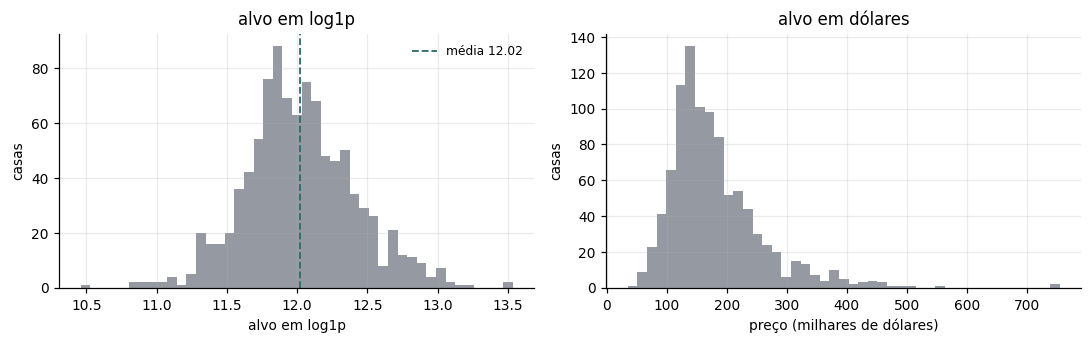

REFERÊNCIAS (escala log1p)

  chutar a média do treino   : MAE 0.3151
  chutar a mediana do treino : MAE 0.3156

  ReW publicada (Neurocomputing 416, Tabela 2): MAE 0.278

  variância do alvo no treino: 0.1537   desvio 0.3920
  0.278 em log1p equivale a 32.0% de erro relativo


In [77]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_train, bins=45, color=COR_REF, alpha=.9)
ax[0].axvline(y_train.mean(), color=COR_KAL, ls="--", lw=1.2, label=f"média {y_train.mean():.2f}")
ax[0].set(xlabel="alvo em log1p", ylabel="casas", title="alvo em log1p")
ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.expm1(y_train) / 1e3, bins=45, color=COR_REF, alpha=.9)
ax[1].set(xlabel="preço (milhares de dólares)", ylabel="casas", title="alvo em dólares")
plt.tight_layout(); plt.show()

print("REFERÊNCIAS (escala log1p)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  ReW publicada (Neurocomputing 416, Tabela 2): MAE {REF_ARTIGO:.3f}")
print(f"\n  variância do alvo no treino: {y_train.var():.4f}   desvio {y_train.std():.4f}")
print(f"  {REF_ARTIGO:.3f} em log1p equivale a {np.expm1(REF_ARTIGO):.1%} de erro relativo")

In [78]:
# Faixas por atributo, usadas por todos os thermometers do experimento.
# Vêm SÓ do treino: o teste não participa da definição dos limiares.
mins = X_train.min(axis=0).tolist()
maxs = X_train.max(axis=0).tolist()
print(f"faixas de {N_ATRIB} atributos, tiradas do treino")
print(f"  exemplo: atributo 0 vai de {mins[0]:.4f} a {maxs[0]:.4f}")

faixas de 332 atributos, tiradas do treino
  exemplo: atributo 0 vai de 8.9366 a 50.2657


---
# Seção 4 — Avaliação vetorizada das duas famílias

As médias em classe da seção 2 são a definição e percorrem as RAM nodes em laço
Python. Aqui elas viram reduções sobre matrizes $(n_{\text{teste}},
n_{\text{rams}})$, o que é o que torna o experimento viável. A célula seguinte
confere as doze contra as classes: a diferença tem de ser de arredondamento e o
padrão de NaN tem de ser o mesmo.

A memória da ReW também é montada de forma vetorizada, com `np.bincount` sobre
os slots, o que é exatamente somar 1 no contador e $y_i$ na soma.

In [79]:
def memoria_rew(indice, y):
    """Contador e soma por célula, sem laço: bincount sobre os slots."""
    y = np.asarray(y, dtype=float)
    plano = indice.slots_fit.ravel()
    n_rams = indice.slots_fit.shape[1]
    cont = np.bincount(plano, minlength=indice.n_celulas).astype(float)
    soma = np.bincount(plano, weights=np.repeat(y, n_rams),
                       minlength=indice.n_celulas)
    return cont, soma


def coleta_rew(cont, soma, slots):
    """(contador, soma, mask) por exemplo e RAM node."""
    ok = slots >= 0
    s = np.where(ok, slots, 0)
    return np.where(ok, cont[s], 0.0), np.where(ok, soma[s], 0.0), ok


def medias_rew_vet(Cont, Soma, V, nomes, n_rams):
    """Família ReW: mu = soma/contador, sem peso, sobre células com contador>0."""
    ok = V & (Cont > 0)
    mu = np.where(ok, Soma / np.where(ok, Cont, 1.0), np.nan)
    m = ok.sum(1).astype(float)
    tem = m > 0
    fin = lambda v, val: np.where(val, v, 0.0)
    out = {}

    if "SimpleMean" in nomes:
        sc = np.where(V, Cont, 0.0).sum(1)
        out["SimpleMean"] = np.where(sc > 0,
                                     np.where(V, Soma, 0.0).sum(1) / np.where(sc > 0, sc, 1), 0.0)
    if "PowerMean(2)" in nomes:
        s = np.where(ok, mu ** 2, 0.0).sum(1)
        out["PowerMean(2)"] = fin(np.sqrt(s / np.where(tem, m, 1)), tem)
    if "ExponentialMean" in nomes:
        s = 1.0 + np.where(ok, np.exp(np.where(ok, mu, 0.0)), 0.0).sum(1)
        out["ExponentialMean"] = fin(np.log(s / np.where(tem, m, 1)), tem)

    ok2 = ok & (mu != 0)                       # harmônicas: guarda mu != 0
    m2 = ok2.sum(1).astype(float); tem2 = m2 > 0
    mus = np.where(ok2, mu, 1.0)
    if "HarmonicMean" in nomes:
        s = np.where(ok2, 1.0 / mus, 0.0).sum(1)
        out["HarmonicMean"] = np.where(s > 0, m2 / np.where(s > 0, s, 1), 0.0)
    if "HarmonicPower(2)" in nomes:
        s = np.where(ok2, 1.0 / mus ** 2, 0.0).sum(1)
        out["HarmonicPower(2)"] = np.where(s > 0, np.sqrt(m2 / np.where(s > 0, s, 1)), 0.0)

    if "Median" in nomes:
        # porte do Median::calculate do wisardpkg: NaN onde contador=0, ordenados
        # no fim, e índice deslocado em um. n é o total de RAM nodes.
        S = np.sort(mu, axis=1)                # np.sort põe NaN no fim
        n = n_rams
        if n % 2 == 0:
            i = n // 2
            out["Median"] = ((S[:, i] + S[:, i + 1]) / 2.0 if i + 1 < n
                             else np.full(len(S), np.nan))
        else:
            i = (n - 1) // 2 + 1
            out["Median"] = S[:, i] if i < n else np.full(len(S), np.nan)
    return out


def medias_kal_vet(Cc, Yy, V, nomes):
    """Família R-KalWeNN: y ponderado por c, normalizado por sum(c)."""
    Cm = np.where(V, Cc, 0.0)
    sc = Cm.sum(1); ok = sc > 0
    V2 = V & (Yy > 0)
    Cm2 = np.where(V2, Cc, 0.0); sc2 = Cm2.sum(1)
    Yp = np.where(V2, Yy, 1.0)
    fin = lambda v, val: np.where(val, v, np.nan)
    out = {}
    if "KSimpleMean" in nomes:
        out["KSimpleMean"] = fin((Cm * Yy).sum(1) / np.where(ok, sc, 1), ok)
    if "KPowerMean(2)" in nomes:
        out["KPowerMean(2)"] = fin(np.sqrt((Cm * Yy ** 2).sum(1) / np.where(ok, sc, 1)), ok)
    if "KHarmonicMean" in nomes:
        s = (Cm2 / Yp).sum(1); o2 = s > 0
        out["KHarmonicMean"] = fin(sc2 / np.where(o2, s, 1), o2)
    if "KHarmonicPower(2)" in nomes:
        s = (Cm2 / Yp ** 2).sum(1); o2 = s > 0
        out["KHarmonicPower(2)"] = fin(np.sqrt(sc2 / np.where(o2, s, 1)), o2)
    if "KExponentialMean" in nomes:
        out["KExponentialMean"] = fin(np.log((Cm * np.exp(Yy)).sum(1) / np.where(ok, sc, 1)), ok)
    if "KMedian" in nomes:
        o = np.argsort(Yy, axis=1, kind="stable")
        Cs = np.take_along_axis(Cm, o, 1); Ys = np.take_along_axis(Yy, o, 1)
        idx = (np.cumsum(Cs, axis=1) >= (sc / 2.0)[:, None]).argmax(1)
        out["KMedian"] = fin(Ys[np.arange(len(Yy)), idx], ok)
    return out


def coleta_kal(modelo, slots):
    ok = slots >= 0
    s = np.where(ok, slots, 0)
    return modelo._C[s], modelo._Y[s], ok


print("avaliação vetorizada definida para as duas famílias")

avaliação vetorizada definida para as duas famílias


In [80]:
# confere as doze contra as classes da seção 2
_t, _a = 20, 8
_dt = DynamicThermometer([_t] * N_ATRIB, mins, maxs)
_Xtr, _Xte = _dt.transform(X_train), _dt.transform(X_test)
_map = sorteia_mapping(_Xtr.shape[1], _a, seed=0)
_ret = Retina(_a, _map)
_idx = IndiceRK(_ret, _ret.enderecos(_Xtr))
_sl = _idx.slots(_ret.enderecos(_Xte))

print(f"conferência em therm {_t}, address {_a}, {_ret.n_rams} RAM nodes\n")
print(f"{'família':<12}{'média':<20}{'max|dif|':>12}{'NaN discord.':>14}")
_falhas = 0

_cont, _soma = memoria_rew(_idx, y_train)
_Ct, _St, _V = coleta_rew(_cont, _soma, _sl)
_vec = medias_rew_vet(_Ct, _St, _V, EXP_MEDIAS_REW, _ret.n_rams)
_rw = RegressionWiSARD(_a, medias_rew()["SimpleMean"], _map).fit(_Xtr, y_train)
for _k in EXP_MEDIAS_REW:
    _rw.mean = medias_rew()[_k]
    _ref = _rw.predict(_Xte)
    _d = float(np.nanmax(np.abs(_vec[_k] - _ref)))
    _mm = int((np.isfinite(_vec[_k]) != np.isfinite(_ref)).sum())
    _falhas += (_d > 1e-9 or _mm > 0)
    print(f"{'ReW':<12}{_k:<20}{_d:>12.3e}{_mm:>14}")

_m = RKalWeNN(_a, _map, seed=0, indice=_idx, passo_predicao=EXP_PASSO_PREDICAO).fit(y=y_train)
_Cc, _Yy, _Vk = coleta_kal(_m, _sl)
_vk = medias_kal_vet(_Cc, _Yy, _Vk, EXP_MEDIAS_KAL)
for _k in EXP_MEDIAS_KAL:
    _md = medias_kal()[_k]
    _ref = np.array([_md.calculate(list(zip(_Cc[i][_Vk[i]], _Yy[i][_Vk[i]])))
                     if _Vk[i].any() else np.nan for i in range(len(_Cc))])
    _amb = np.isfinite(_vk[_k]) & np.isfinite(_ref)
    _d = float(np.abs(_vk[_k][_amb] - _ref[_amb]).max()) if _amb.any() else 0.0
    _mm = int((np.isfinite(_vk[_k]) != np.isfinite(_ref)).sum())
    _falhas += (_d > 1e-9 or _mm > 0)
    print(f"{'R-KalWeNN':<12}{_k:<20}{_d:>12.3e}{_mm:>14}")

print(f"\n{len(EXP_MEDIAS_REW)+len(EXP_MEDIAS_KAL)-_falhas}/"
      f"{len(EXP_MEDIAS_REW)+len(EXP_MEDIAS_KAL)} conferem")

conferência em therm 20, address 8, 830 RAM nodes

família     média                   max|dif|  NaN discord.
ReW         SimpleMean             2.842e-14             0
ReW         PowerMean(2)           1.421e-14             0
ReW         HarmonicMean           2.309e-14             0
ReW         HarmonicPower(2)       1.599e-14             0
ReW         ExponentialMean        1.776e-15             0
ReW         Median                 0.000e+00             0
R-KalWeNN   KSimpleMean            4.619e-14             0
R-KalWeNN   KPowerMean(2)          2.487e-14             0
R-KalWeNN   KHarmonicMean          3.730e-14             0
R-KalWeNN   KHarmonicPower(2)      1.954e-14             0
R-KalWeNN   KExponentialMean       3.553e-15             0
R-KalWeNN   KMedian                0.000e+00             0

12/12 conferem


---
# Seção 5 — O experimento

Para cada par (thermometer, address) e cada seed: binariza, sorteia o `mapping`
com aquela seed e monta o índice. Os dois modelos recebem exatamente o mesmo
`mapping`.

A ReW é ajustada uma vez e avaliada nas seis médias dela. O R-KalWeNN é
ajustado uma vez por configuração de covariância e avaliado nas seis médias
dele, que saem do mesmo ajuste porque a média só age na predição.

In [81]:
def metricas(y_ref, p):
    nf = int((~np.isfinite(p)).sum())
    if nf:
        bons = p[np.isfinite(p)]
        p = np.where(np.isfinite(p), p, bons.mean() if len(bons) else 0.0)
    ss = float(np.sum((y_ref - y_ref.mean()) ** 2))
    return (mean_absolute_error(y_ref, p),
            float(np.sqrt(mean_squared_error(y_ref, p))),
            1.0 - float(np.sum((y_ref - p) ** 2)) / ss, nf)


combos = list(product(EXP_Q_C, EXP_R_C, EXP_P0_C, EXP_Q_Y, EXP_R_Y, EXP_P0_Y))
linhas, t0 = [], time.perf_counter()
therm_atual = None

for t, a in PARES:
    if t != therm_atual:
        dtm = DynamicThermometer([t] * N_ATRIB, mins, maxs)
        Xtr_s, Xte_s = dtm.transform(X_train), dtm.transform(X_test)
        therm_atual = t
    for s in EXP_SEEDS:
        mp = sorteia_mapping(Xtr_s.shape[1], a, seed=s)      # o MESMO para os dois
        ret = Retina(a, mp)
        idx = IndiceRK(ret, ret.enderecos(Xtr_s))
        sl = idx.slots(ret.enderecos(Xte_s))

        cont, soma = memoria_rew(idx, y_train)
        Ct, St, V = coleta_rew(cont, soma, sl)
        for nome, p in medias_rew_vet(Ct, St, V, EXP_MEDIAS_REW, ret.n_rams).items():
            mae, rmse, r2, nf = metricas(y_test, p)
            linhas.append(dict(modelo="ReW", therm=t, address=a, n_rams=ret.n_rams,
                               seed=s, media=nome, q_c=np.nan, r_c=np.nan, p0_c=np.nan,
                               q_y=np.nan, r_y=np.nan, p0_y=np.nan,
                               MAE=mae, RMSE=rmse, R2=r2, nao_finito=nf))

        for qc, rc, p0c, qy, ry, p0y in combos:
            m = RKalWeNN(a, mp, q_c=qc, r_c=rc, p0_c=p0c, q_y=qy, r_y=ry, p0_y=p0y,
                         x0_c=EXP_X0_C, x0_y=EXP_X0_Y, seed=s, indice=idx,
                         passo_predicao=EXP_PASSO_PREDICAO).fit(y=y_train)
            Cc, Yy, Vk = coleta_kal(m, sl)
            for nome, p in medias_kal_vet(Cc, Yy, Vk, EXP_MEDIAS_KAL).items():
                mae, rmse, r2, nf = metricas(y_test, p)
                linhas.append(dict(modelo="R-KalWeNN", therm=t, address=a,
                                   n_rams=ret.n_rams, seed=s, media=nome,
                                   q_c=qc, r_c=rc, p0_c=p0c, q_y=qy, r_y=ry, p0_y=p0y, MAE=mae, RMSE=rmse, R2=r2, nao_finito=nf))
    el = time.perf_counter() - t0
    feito = PARES.index((t, a)) + 1
    print(f"  therm {t:>2} address {a:>2} ({ret.n_rams:>5} rams)  {feito}/{len(PARES)}  "
          f"{el/60:.1f} min, faltam ~{el/feito*(len(PARES)-feito)/60:.0f} min")

comp = pd.DataFrame(linhas)
comp.to_csv(EXP_ARQUIVO, index=False)
print(f"\nconcluído em {(time.perf_counter()-t0)/60:.1f} min, "
      f"{len(comp):,} linhas em {EXP_ARQUIVO}")

  therm 20 address  6 ( 1106 rams)  1/9  1.0 min, faltam ~8 min
  therm 20 address  8 (  830 rams)  2/9  1.6 min, faltam ~6 min
  therm 20 address 12 (  553 rams)  3/9  2.1 min, faltam ~4 min
  therm 25 address  6 ( 1383 rams)  4/9  3.0 min, faltam ~4 min
  therm 25 address  8 ( 1037 rams)  5/9  3.8 min, faltam ~3 min
  therm 25 address 12 (  691 rams)  6/9  4.6 min, faltam ~2 min
  therm 27 address  6 ( 1494 rams)  7/9  5.7 min, faltam ~2 min
  therm 27 address  8 ( 1120 rams)  8/9  6.5 min, faltam ~1 min
  therm 27 address 12 (  747 rams)  9/9  7.1 min, faltam ~0 min

concluído em 7.1 min, 10,530 linhas em comparacao_rew_rkalwenn.csv


---
# Seção 6 — Resultados

## 6.1 Os dois lado a lado, por configuração de codificação

In [82]:
if "comp" not in globals():
    comp = pd.read_csv(EXP_ARQUIVO)

comp["cfg"] = comp.therm.astype(str) + "/" + comp.address.astype(str)
ordem_cfg = [f"{t}/{a}" for t, a in PARES]

res = (comp.groupby(["cfg", "modelo"]).MAE.agg(["min", "median", "max"])
       .unstack("modelo"))
res = res.reindex(ordem_cfg)
print("MAE por configuração  (therm/address)\n")
print(res.to_string(float_format=lambda v: f"{v:.4f}"))

melhor = comp.loc[comp.groupby(["cfg", "modelo"]).MAE.idxmin()]
print("\n\nMELHOR DE CADA MODELO, por configuração\n")
cols = ["cfg", "n_rams", "modelo", "media", "q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y", "MAE", "R2"]
print(melhor.sort_values(["cfg", "modelo"])[cols].to_string(
    index=False, float_format=lambda v: f"{v:.4g}"))

piv = melhor.pivot_table(index="cfg", columns="modelo", values="MAE").reindex(ordem_cfg)
piv["ganho_%"] = (piv["R-KalWeNN"] / piv["ReW"] - 1) * 100
print("\n\nGANHO DO R-KalWeNN SOBRE A ReW, no melhor de cada um\n")
print(piv.to_string(float_format=lambda v: f"{v:.4f}"))

MAE por configuração  (therm/address)

             min           median              max       
modelo R-KalWeNN    ReW R-KalWeNN    ReW R-KalWeNN    ReW
cfg                                                      
20/6      0.2408 0.2474    0.2555 0.2484    0.2891 0.2868
20/8      0.2269 0.2318    0.2433 0.2330    0.3585 0.2784
20/12     0.2025 0.2079    0.2194 0.2095    0.6546 0.2632
25/6      0.2403 0.2475    0.2555 0.2483    0.2894 0.2873
25/8      0.2258 0.2320    0.2430 0.2329    0.3610 0.2781
25/12     0.2004 0.2074    0.2185 0.2082    0.6431 0.2610
27/6      0.2408 0.2479    0.2555 0.2482    0.2900 0.2866
27/8      0.2265 0.2322    0.2435 0.2328    0.3545 0.2777
27/12     0.2025 0.2076    0.2192 0.2087    0.6421 0.2622


MELHOR DE CADA MODELO, por configuração

  cfg  n_rams    modelo             media    q_c  r_c  p0_c  q_y  r_y  p0_y    MAE     R2
20/12     553 R-KalWeNN           KMedian 0.0001  0.1     1 0.15    1    12 0.2025 0.5373
20/12     553       ReW   ExponentialMean 

## 6.2 Variação do MAE de cada modelo com os hiperparâmetros que ele tem

A caixa é a distribuição do MAE sobre tudo o que aquele modelo varre naquela
configuração: para a ReW, as seis médias dela; para o R-KalWeNN, as covariâncias
e as seis médias dele. O losango marca o melhor de cada um.

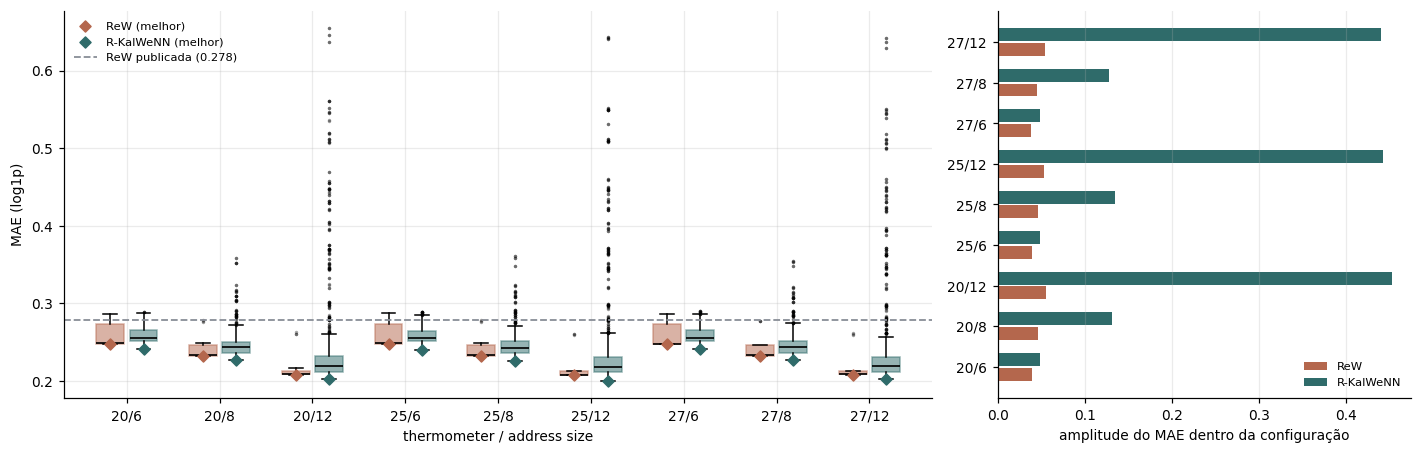

In [83]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2),
                       gridspec_kw={"width_ratios": [2.1, 1]})

x = np.arange(len(ordem_cfg))
for k, (mod, cor, off) in enumerate([("ReW", COR_REW, -0.18), ("R-KalWeNN", COR_KAL, 0.18)]):
    dados = [comp[(comp.cfg == c) & (comp.modelo == mod)].MAE.values for c in ordem_cfg]
    bp = ax[0].boxplot(dados, positions=x + off, widths=.3, patch_artist=True,
                       medianprops=dict(color="black", lw=1.1),
                       flierprops=dict(marker=".", ms=2.5, alpha=.35))
    for caixa in bp["boxes"]:
        caixa.set(facecolor=cor, alpha=.5, edgecolor=cor)
    ax[0].scatter(x + off, [d.min() for d in dados], marker="D", s=26,
                  color=cor, zorder=5, label=f"{mod} (melhor)")
ax[0].axhline(REF_ARTIGO, color=COR_REF, ls="--", lw=1.2, label=f"ReW publicada ({REF_ARTIGO})")
ax[0].set(xticks=x, xticklabels=ordem_cfg, xlabel="thermometer / address size",
          ylabel="MAE (log1p)")
ax[0].legend(frameon=False, fontsize=7.5)

larg = comp.groupby(["cfg", "modelo"]).MAE.agg(lambda s: s.max() - s.min()).unstack()
larg = larg.reindex(ordem_cfg)
ax[1].barh(x - 0.18, larg["ReW"], height=.32, color=COR_REW, label="ReW")
ax[1].barh(x + 0.18, larg["R-KalWeNN"], height=.32, color=COR_KAL, label="R-KalWeNN")
ax[1].set(yticks=x, yticklabels=ordem_cfg, xlabel="amplitude do MAE dentro da configuração")
ax[1].grid(axis="y", visible=False); ax[1].legend(frameon=False, fontsize=7.5)
plt.tight_layout(); plt.show()

## 6.3 Variação com os hiperparâmetros do Kalman

Só o R-KalWeNN. Uma caixa por nível, com a linha do melhor de cada nível. As
razões `q/r` e `p0/r` aparecem junto porque, com os estados iniciais em zero,
são elas que definem o modelo.

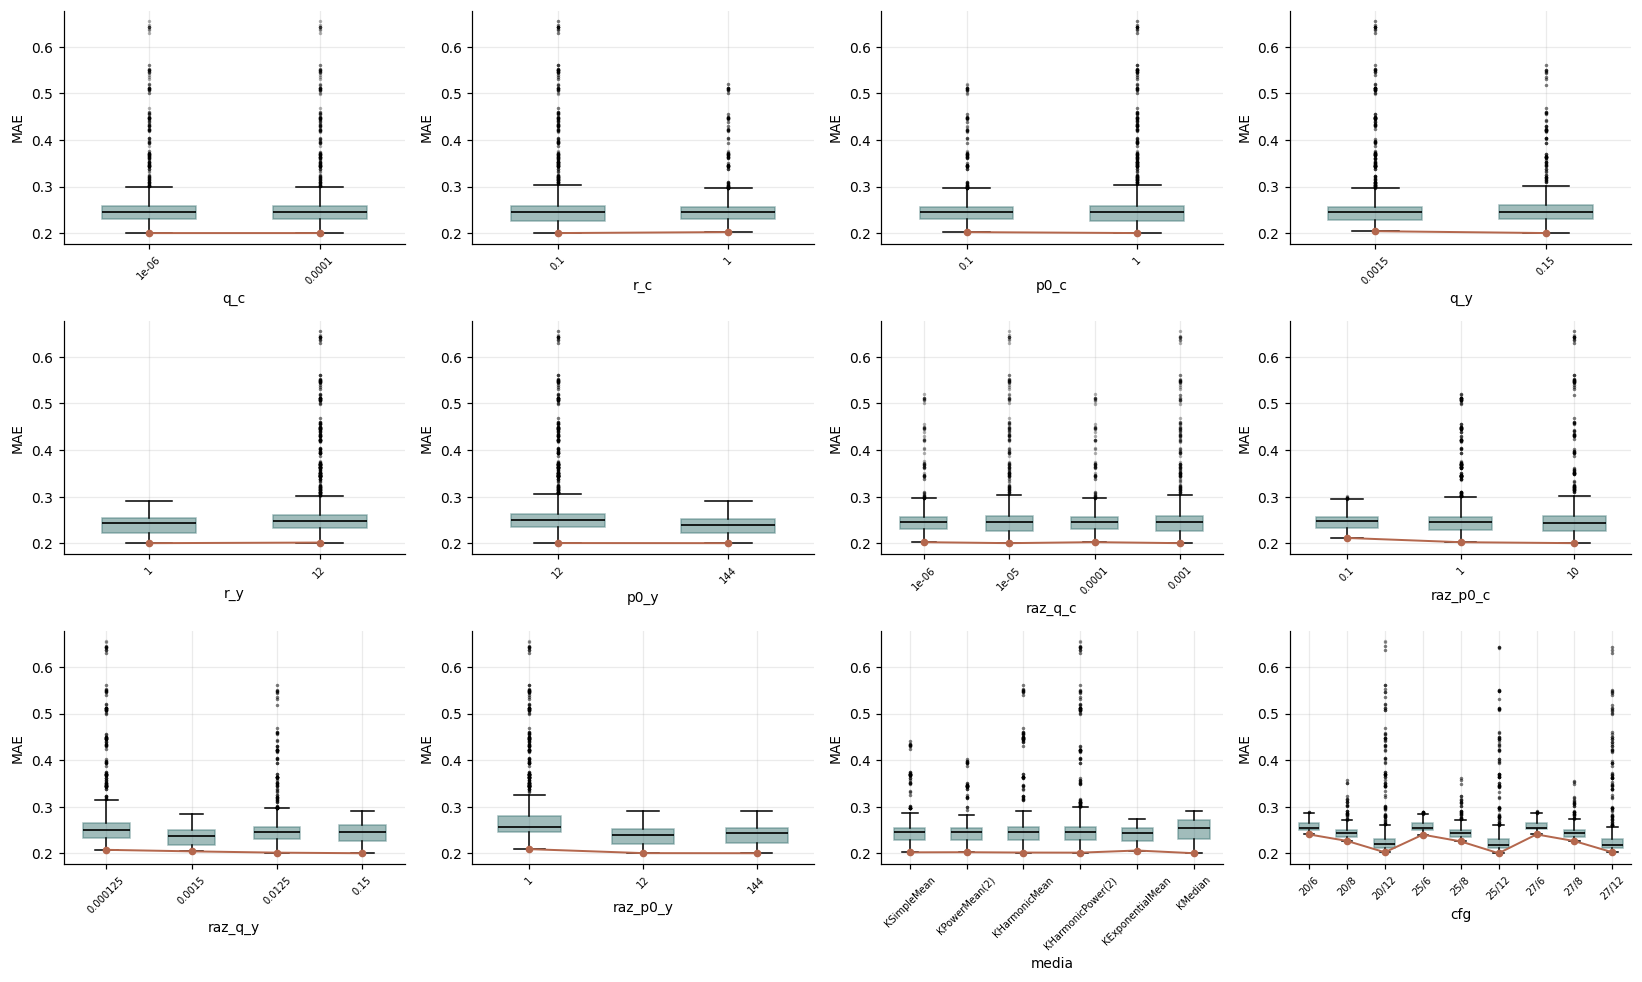

amplitude do melhor MAE por eixo, só R-KalWeNN

  cfg            0.0404
  raz_p0_c       0.0112
  raz_p0_y       0.0088
  raz_q_y        0.0073
  media          0.0058
  raz_q_c        0.0021


In [84]:
k = comp[comp.modelo == "R-KalWeNN"].copy()
k["raz_q_c"] = k.q_c / k.r_c
k["raz_p0_c"] = k.p0_c / k.r_c
k["raz_q_y"] = k.q_y / k.r_y
k["raz_p0_y"] = k.p0_y / k.r_y

EIXOS = [("q_c", EXP_Q_C), ("r_c", EXP_R_C), ("p0_c", EXP_P0_C),
         ("q_y", EXP_Q_Y), ("r_y", EXP_R_Y), ("p0_y", EXP_P0_Y),
         ("raz_q_c", sorted(k.raz_q_c.unique())),
         ("raz_p0_c", sorted(k.raz_p0_c.unique())),
         ("raz_q_y", sorted(k.raz_q_y.unique())),
         ("raz_p0_y", sorted(k.raz_p0_y.unique())),
         ("media", EXP_MEDIAS_KAL),
         ("cfg", ordem_cfg)]

fig, ax = plt.subplots(3, 4, figsize=(15, 9))
def _fatia(col, v):
    return (k.loc[np.isclose(k[col], v), "MAE"].values if isinstance(v, float)
            else k.loc[k[col] == v, "MAE"].values)

for a_, (col, niveis) in zip(ax.ravel(), EIXOS):
    par = [(v, _fatia(col, v)) for v in niveis]
    par = [(v, d) for v, d in par if len(d)]
    niv = [v for v, _ in par]
    dados = [d for _, d in par]
    bp = a_.boxplot(dados, positions=range(len(dados)), widths=.55, patch_artist=True,
                    medianprops=dict(color="black", lw=1.1),
                    flierprops=dict(marker=".", ms=2.5, alpha=.3))
    for caixa in bp["boxes"]:
        caixa.set(facecolor=COR_KAL, alpha=.45, edgecolor=COR_KAL)
    a_.plot(range(len(dados)), [d.min() for d in dados], "o-", color=COR_REW,
            ms=4, lw=1.3)
    rot = [f"{v:g}" if isinstance(v, float) else str(v) for v in niv]
    a_.set(xticks=range(len(dados)), xticklabels=rot, xlabel=col, ylabel="MAE")
    a_.tick_params(axis="x", labelrotation=45, labelsize=6.5)
plt.tight_layout(); plt.show()

amp = {c: float(k.groupby(c).MAE.min().max() - k.groupby(c).MAE.min().min())
       for c in ["raz_q_c", "raz_p0_c", "raz_q_y", "raz_p0_y", "media", "cfg"]}
print("amplitude do melhor MAE por eixo, só R-KalWeNN\n")
for c, v in sorted(amp.items(), key=lambda t: -t[1]):
    print(f"  {c:<12}{v:>9.4f}")